In [2]:

%pip install pandas numpy matplotlib seaborn pillow scikit-learn tqdm


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

# Notebook notebooks/ klasöründeyse proje köküne çık.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
IMAGE_DIR = DATA_DIR / "224x224"
METADATA_DIR = DATA_DIR / "metadata"

print("Proje dizini:", PROJECT_ROOT)
print("Görsel klasörü mevcut mu?:", IMAGE_DIR.exists())
print("Etiket klasörü mevcut mu?:", METADATA_DIR.exists())

Proje dizini: c:\Users\amine\Projects\book-cover-classification-bookstat
Görsel klasörü mevcut mu?: True
Etiket klasörü mevcut mu?: True


In [4]:
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    path
    for path in IMAGE_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
]

print("Bulunan görsel sayısı:", len(image_paths))
print("\nİlk 5 görsel:")

for path in image_paths[:5]:
    print(path.name)

print("\nDosya uzantıları:")
extension_counts = Counter(path.suffix.lower() for path in image_paths)
for extension, count in extension_counts.items():
    print(f"{extension}: {count}")

Bulunan görsel sayısı: 57000

İlk 5 görsel:
0001484524.jpg
0001956604.jpg
0002158434.jpg
0002163306.jpg
0002169681.jpg

Dosya uzantıları:
.jpg: 57000


In [5]:
print("Metadata klasöründeki dosyalar:")

for path in sorted(METADATA_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name} — {path.stat().st_size:,} bayt")

Metadata klasöründeki dosyalar:
book30-listing-test.csv — 1,080,960 bayt
book30-listing-train.csv — 9,728,786 bayt
bookcover30-labels-test.txt — 100,700 bayt
bookcover30-labels-train.txt — 906,300 bayt


In [6]:

# Etiket dosyalarının ilk 5 satırını inceleyelim.
label_files = [
    METADATA_DIR / "bookcover30-labels-train.txt",
    METADATA_DIR / "bookcover30-labels-test.txt",
]

for file_path in label_files:
    print(f"\n{'=' * 60}")
    print(f"Dosya: {file_path.name}")

    with file_path.open("r", encoding="utf-8-sig") as file:
        for i, line in enumerate(file):
            if i == 5:
                break
            print(repr(line.rstrip("\n\r")))



Dosya: bookcover30-labels-train.txt
'1588345297.jpg 1'
'1404803335.jpg 4'
'1446276082.jpg 10'
'1491522666.jpg 9'
'0970096410.jpg 26'

Dosya: bookcover30-labels-test.txt
'044310073X.jpg 16'
'1438005687.jpg 28'
'0060750715.jpg 1'
'1580237959.jpg 21'
'0135137829.jpg 0'


In [7]:

import pandas as pd

csv_files = [
    METADATA_DIR / "book30-listing-train.csv",
    METADATA_DIR / "book30-listing-test.csv",
]

for file_path in csv_files:
    print(f"\n{'=' * 60}")
    print(f"Dosya: {file_path.name}")

    df_preview = None
    used_encoding = None

    for encoding in ["utf-8-sig", "cp1252", "latin1"]:
        try:
            df_preview = pd.read_csv(file_path, encoding=encoding)
            used_encoding = encoding
            break
        except UnicodeDecodeError:
            continue

    if df_preview is None:
        print("Dosya okunamadı; kodlamayı ayrıca incelememiz gerekiyor.")
        continue

    print("Kullanılan kodlama:", used_encoding)
    print("Satır ve sütun sayısı:", df_preview.shape)
    print("Sütun isimleri:", df_preview.columns.tolist())
    display(df_preview.head(3))




Dosya: book30-listing-train.csv
Kullanılan kodlama: latin1
Satır ve sütun sayısı: (51299, 7)
Sütun isimleri: ['1588345297', '1588345297.jpg', 'http://ecx.images-amazon.com/images/I/51l6XIoa3rL.jpg', 'With Schwarzkopf: Life Lessons of The Bear', 'Gus Lee', '1', 'Biographies & Memoirs']


,1588345297,1588345297.jpg,http://ecx.images-amazon.com/images/I/51l6XIoa3rL.jpg,With Schwarzkopf: Life Lessons of The Bear,Gus Lee,1,Biographies & Memoirs
0,1404803335,1404803335.jpg,http://ecx.images-amazon.com/images/I/51UJnL3T...,"Magnets: Pulling Together, Pushing Apart (Amaz...",Natalie M. Rosinsky,4,Children's Books
1,1446276082,1446276082.jpg,http://ecx.images-amazon.com/images/I/51MGUKhk...,Energy Security (SAGE Library of International...,NaN,10,Engineering & Transportation
2,1491522666,1491522666.jpg,http://ecx.images-amazon.com/images/I/51qKvjsi...,An Amish Gathering: Life in Lancaster County,Beth Wiseman,9,Christian Books & Bibles



Dosya: book30-listing-test.csv
Kullanılan kodlama: latin1
Satır ve sütun sayısı: (5699, 7)
Sütun isimleri: ['044310073X', '044310073X.jpg', 'http://ecx.images-amazon.com/images/I/41kSLEoswsL.jpg', 'Oral and Maxillofacial Surgery: An Objective-Based Textbook, 2e', 'Unnamed: 4', '16', 'Medical Books']


,044310073X,044310073X.jpg,http://ecx.images-amazon.com/images/I/41kSLEoswsL.jpg,"Oral and Maxillofacial Surgery: An Objective-Based Textbook, 2e",Unnamed: 4,16,Medical Books
0,1438005687,1438005687.jpg,http://ecx.images-amazon.com/images/I/510l0qhi...,"Barron's GRE, 21st Edition",Sharon Weiner Green M.A.,28,Test Preparation
1,60750715,0060750715.jpg,http://ecx.images-amazon.com/images/I/51p5aUY%...,George Balanchine: The Ballet Maker (Eminent L...,Robert Gottlieb,1,Biographies & Memoirs
2,1580237959,1580237959.jpg,http://ecx.images-amazon.com/images/I/51pum0eW...,"A Partner in Holiness: Deepening Mindfulness, ...",Rabbi Jonathan P. Slater DMin,21,Religion & Spirituality


In [8]:

for filename in [
    "bookcover30-labels-train.txt",
    "bookcover30-labels-test.txt",
]:
    file_path = METADATA_DIR / filename

    print(f"\n--- {filename} ---")

    with file_path.open("r", encoding="utf-8-sig") as file:
        for i, line in enumerate(file):
            if i >= 5:
                break
            print(repr(line.rstrip()))



--- bookcover30-labels-train.txt ---
'1588345297.jpg 1'
'1404803335.jpg 4'
'1446276082.jpg 10'
'1491522666.jpg 9'
'0970096410.jpg 26'

--- bookcover30-labels-test.txt ---
'044310073X.jpg 16'
'1438005687.jpg 28'
'0060750715.jpg 1'
'1580237959.jpg 21'
'0135137829.jpg 0'


In [9]:
# Etiket dosyalarını oku: her satır "dosya_adı sınıf_numarası"
def load_labels(file_path):
    records = []

    with file_path.open("r", encoding="utf-8-sig") as file:
        for line_number, line in enumerate(file, start=1):
            parts = line.strip().split()

            if not parts:
                continue

            if len(parts) != 2:
                print(f"Beklenmeyen satır: {file_path.name}, satır {line_number}: {line!r}")
                continue

            filename, label = parts
            records.append((filename, int(label)))

    return pd.DataFrame(records, columns=["filename", "label"])


train_df = load_labels(METADATA_DIR / "bookcover30-labels-train.txt")
test_df = load_labels(METADATA_DIR / "bookcover30-labels-test.txt")

print("Eğitim etiketi sayısı:", len(train_df))
print("Test etiketi sayısı:", len(test_df))
print("Toplam etiket sayısı:", len(train_df) + len(test_df))

print("\nEğitim sınıf sayısı:", train_df["label"].nunique())
print("Test sınıf sayısı:", test_df["label"].nunique())
print("Eğitim sınıf numaraları:", sorted(train_df["label"].unique()))
print("Test sınıf numaraları:", sorted(test_df["label"].unique()))

print("\nİlk 5 eğitim etiketi:")
display(train_df.head())


Eğitim etiketi sayısı: 51300
Test etiketi sayısı: 5700
Toplam etiket sayısı: 57000

Eğitim sınıf sayısı: 30
Test sınıf sayısı: 30
Eğitim sınıf numaraları: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29)]
Test sınıf numaraları: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29)]


,filename,label
0,1588345297.jpg,1
1,1404803335.jpg,4
2,1446276082.jpg,10
3,1491522666.jpg,9
4,0970096410.jpg,26


In [10]:

# Görsel klasöründeki dosya adlarını küme olarak tutuyoruz.
image_names = {path.name for path in IMAGE_DIR.iterdir() if path.is_file()}

train_names = set(train_df["filename"])
test_names = set(test_df["filename"])

print("Klasördeki görsel sayısı:", len(image_names))
print("Eğitim etiketlerinde eşleşen görsel:", len(train_names & image_names))
print("Test etiketlerinde eşleşen görsel:", len(test_names & image_names))

print("\nEğitim etiketlerinde görseli bulunamayan:",
      len(train_names - image_names))
print("Test etiketlerinde görseli bulunamayan:",
      len(test_names - image_names))

print("\nTekrarlanan eğitim dosya adı:", train_df["filename"].duplicated().sum())
print("Tekrarlanan test dosya adı:", test_df["filename"].duplicated().sum())
print("Eğitim-test arasında ortak dosya adı:", len(train_names & test_names))


Klasördeki görsel sayısı: 57000
Eğitim etiketlerinde eşleşen görsel: 51300
Test etiketlerinde eşleşen görsel: 5700

Eğitim etiketlerinde görseli bulunamayan: 0
Test etiketlerinde görseli bulunamayan: 0

Tekrarlanan eğitim dosya adı: 0
Tekrarlanan test dosya adı: 0
Eğitim-test arasında ortak dosya adı: 0


In [11]:

class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
    .rename_axis("class_id")
    .reset_index(name="image_count")
)

display(class_counts)

print("Eğitimde en az örneği olan sınıf:",
      class_counts["image_count"].min())
print("Eğitimde en çok örneği olan sınıf:",
      class_counts["image_count"].max())


,class_id,image_count
0,0,1710
1,1,1710
2,2,1710
3,3,1710
4,4,1710
5,5,1710
6,6,1710
7,7,1710
8,8,1710
9,9,1710


Eğitimde en az örneği olan sınıf: 1710
Eğitimde en çok örneği olan sınıf: 1710


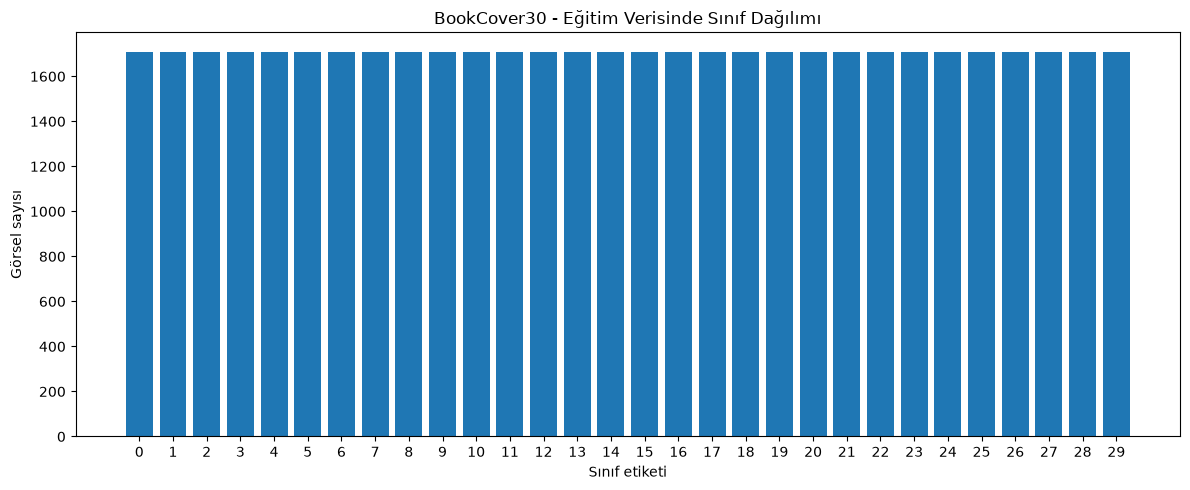

In [12]:

import matplotlib.pyplot as plt

class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title("BookCover30 - Eğitim Verisinde Sınıf Dağılımı")
plt.xlabel("Sınıf etiketi")
plt.ylabel("Görsel sayısı")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:

from PIL import Image
from collections import Counter
from tqdm.auto import tqdm

image_paths = sorted(
    path for path in IMAGE_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

dimension_counts = Counter()
mode_counts = Counter()
corrupt_files = []

for path in tqdm(image_paths, desc="Görseller inceleniyor"):
    try:
        with Image.open(path) as img:
            dimension_counts[img.size] += 1
            mode_counts[img.mode] += 1
            img.verify()
    except Exception:
        corrupt_files.append(path.name)

print("Farklı görsel boyutu sayısı:", len(dimension_counts))
print("\nEn sık görülen 10 boyut:")
for size, count in dimension_counts.most_common(10):
    print(f"{size[0]} x {size[1]}: {count} görsel")

print("\nRenk modları:")
for mode, count in mode_counts.items():
    print(f"{mode}: {count} görsel")

print("\nAçılamayan veya bozuk dosya sayısı:", len(corrupt_files))
if corrupt_files:
    print("İlk 10 sorunlu dosya:", corrupt_files[:10])


c:\Users\amine\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Görseller inceleniyor: 100%|██████████| 57000/57000 [00:22<00:00, 2581.71it/s]

Farklı görsel boyutu sayısı: 1

En sık görülen 10 boyut:
224 x 224: 57000 görsel

Renk modları:
RGB: 57000 görsel

Açılamayan veya bozuk dosya sayısı: 0


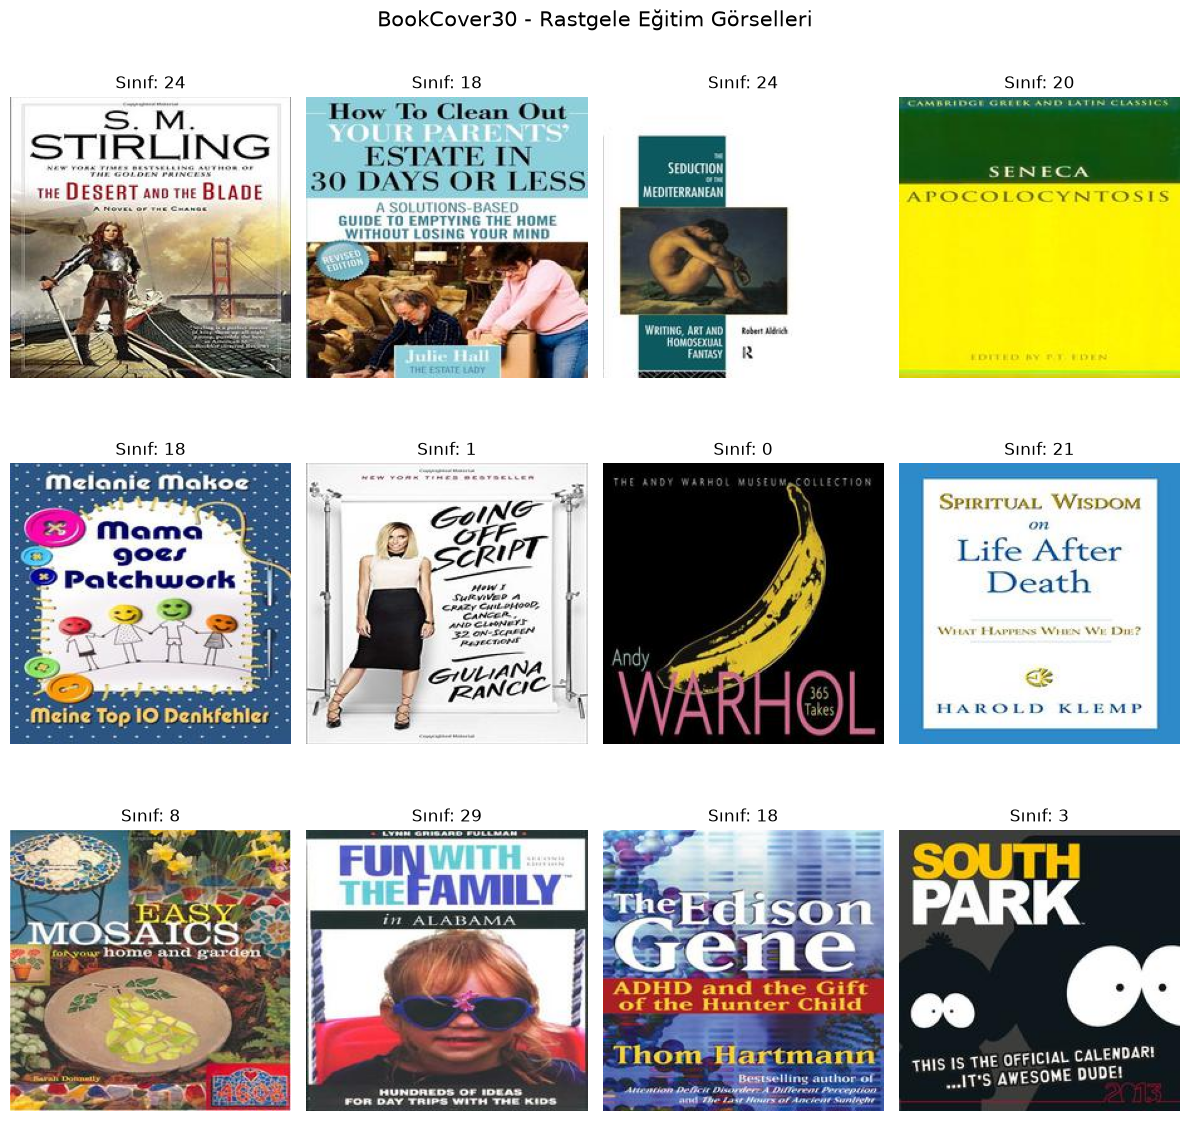

In [14]:

import random

rng = random.Random(42)
sample_rows = train_df.sample(n=12, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(12, 12))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    image_path = IMAGE_DIR / row["filename"]

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(f"Sınıf: {row['label']}")
    ax.axis("off")

plt.suptitle("BookCover30 - Rastgele Eğitim Görselleri", fontsize=15)
plt.tight_layout()
plt.show()


In [15]:

# CSV dosyalarının ilk satırı aslında sütun başlığı değil, veri.
# Bu nedenle header=None kullanıyoruz.
column_names = [
    "book_id",
    "filename",
    "image_url",
    "title",
    "author",
    "rating_or_count",
    "category",
]

train_csv = pd.read_csv(
    METADATA_DIR / "book30-listing-train.csv",
    header=None,
    names=column_names,
    encoding="latin1",
)

test_csv = pd.read_csv(
    METADATA_DIR / "book30-listing-test.csv",
    header=None,
    names=column_names,
    encoding="latin1",
)

# Etiketlerle kategori bilgilerini dosya adı üzerinden birleştir.
train_analysis = train_df.merge(
    train_csv[["filename", "category"]],
    on="filename",
    how="left",
    validate="one_to_one",
)

test_analysis = test_df.merge(
    test_csv[["filename", "category"]],
    on="filename",
    how="left",
    validate="one_to_one",
)

print("Eğitimde eksik kategori:", train_analysis["category"].isna().sum())
print("Testte eksik kategori:", test_analysis["category"].isna().sum())

print("\nSınıf numarası ve kategori eşleşmeleri:")
display(
    train_analysis[["label", "category"]]
    .drop_duplicates()
    .sort_values("label")
    .reset_index(drop=True)
)


Eğitimde eksik kategori: 0
Testte eksik kategori: 0

Sınıf numarası ve kategori eşleşmeleri:


,label,category
0,0,Arts & Photography
1,1,Biographies & Memoirs
2,2,Business & Money
3,3,Calendars
4,4,Children's Books
5,5,Comics & Graphic Novels
6,6,Computers & Technology
7,7,"Cookbooks, Food & Wine"
8,8,"Crafts, Hobbies & Home"
9,9,Christian Books & Bibles


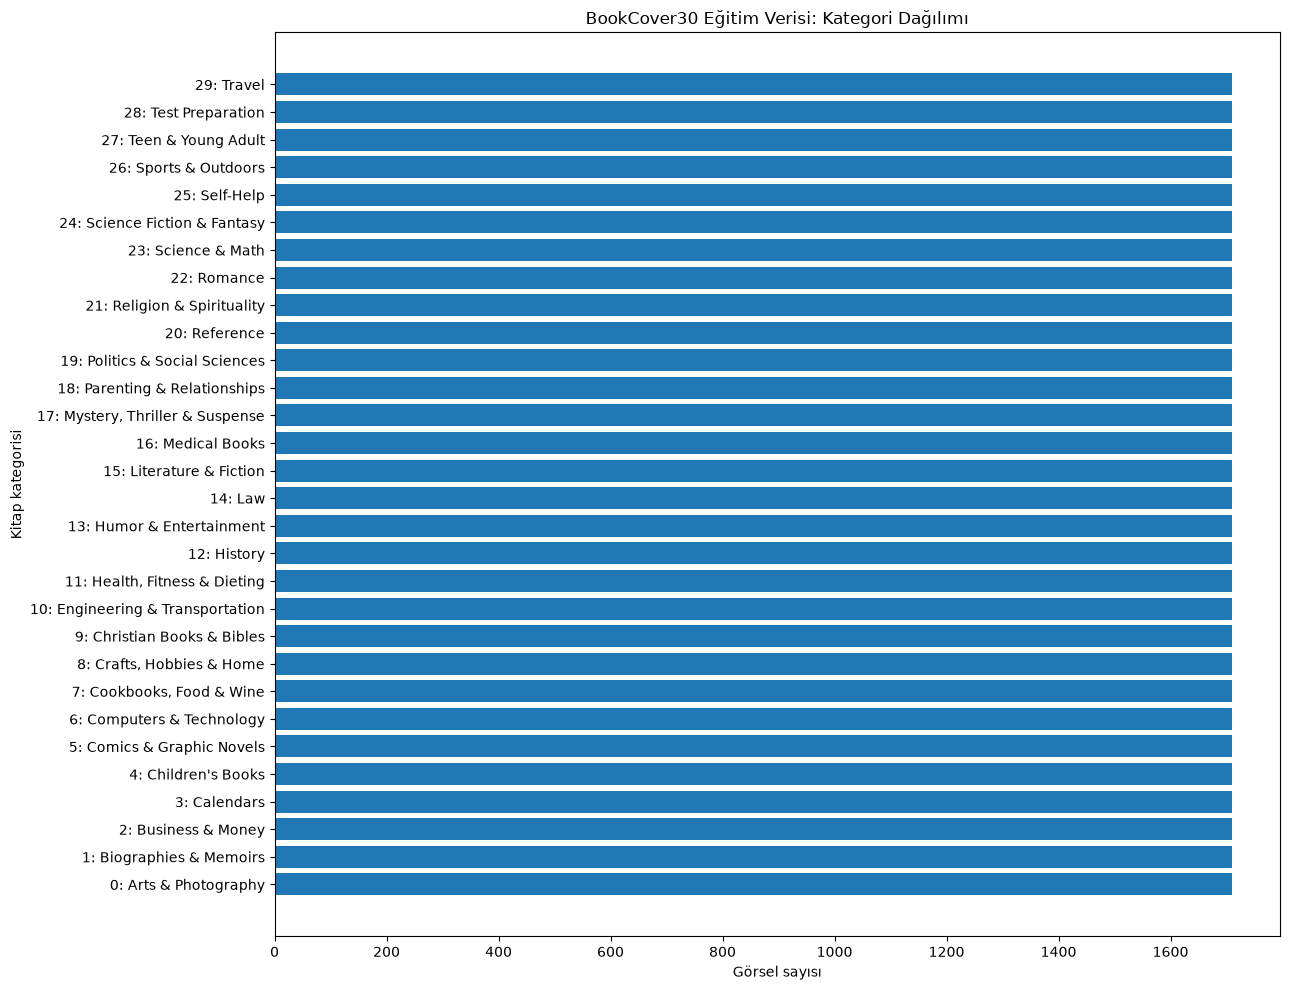

Grafik kaydedildi: c:\Users\amine\Projects\book-cover-classification-bookstat\reports\class_distribution.png


In [16]:
# Her sınıf numarasının kategori adını al
class_names = (
    train_analysis[["label", "category"]]
    .drop_duplicates()
    .set_index("label")["category"]
    .to_dict()
)

class_counts = train_df["label"].value_counts().sort_index()

labels = [
    f"{i}: {class_names[i]}"
    for i in class_counts.index
]

plt.figure(figsize=(13, 10))
plt.barh(labels, class_counts.values)
plt.xlabel("Görsel sayısı")
plt.ylabel("Kitap kategorisi")
plt.title("BookCover30 Eğitim Verisi: Kategori Dağılımı")
plt.tight_layout()

# Grafiği raporlarda kullanmak üzere kaydet
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    REPORTS_DIR / "class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Grafik kaydedildi:", REPORTS_DIR / "class_distribution.png")


In [17]:

summary = """# Veri Seti İncelemesi: BookCover30

## 1. Veri Setine Genel Bakış

Bu projede kitap kapak görüntülerinden kitap kategorilerini
tahmin etmek amacıyla BookCover30 veri seti kullanılmaktadır.

- **Toplam görsel sayısı:** 57.000
- **Eğitim kümesi:** 51.300 görsel (%90)
- **Test kümesi:** 5.700 görsel (%10)
- **Kategori sayısı:** 30
- **Görsel boyutları:** 224 × 224 piksel
- **Renk formatı:** RGB

## 2. Veri Bütünlüğü Kontrolleri

- Etiket dosyalarındaki 57.000 dosya adı mevcut görsellerle eşleşmiştir.
- Dosya adı eşleştirmesinde eksik görsel bulunmamıştır.
- Eğitim etiketlerinde tekrarlanan dosya adı bulunmamıştır.
- Test etiketlerinde tekrarlanan dosya adı bulunmamıştır.
- Eğitim ve test kümeleri arasında ortak dosya adı bulunmamıştır.
- Görsel incelemesinde okunamayan veya bozuk dosya tespit edilmemiştir.

## 3. Kategori Dağılımı

- Her kategoride 1.710 eğitim görseli bulunmaktadır.
- Her kategoride 190 test görseli bulunmaktadır.
- Her kategoride toplam 1.900 görsel bulunmaktadır.

Bu sonuçlar, veri setinin sınıf sayıları bakımından dengeli olduğunu
göstermektedir. Ancak dengeli dağılım, modelin bütün kategorilerde
eşit başarı göstereceği anlamına gelmez.

### Eğitim Kümesinin Kategori Dağılımı

![BookCover30 eğitim kümesi kategori dağılımı](class_distribution.png)

## 4. İlk Değerlendirme

Görsellerin aynı boyutta ve RGB formatında olması, model eğitiminde
standart bir giriş boyutu kullanılmasını kolaylaştırmaktadır.

Bir sonraki aşamada görsellerin ön işleme gereksinimleri,
kategori etiketleri ve kullanılacak sınıflandırma modelleri
değerlendirilecektir.
"""

summary_path = REPORTS_DIR / "veri_seti_incelemesi.md"
summary_path.write_text(summary, encoding="utf-8")

print("Analiz raporu kaydedildi:", summary_path)


Analiz raporu kaydedildi: c:\Users\amine\Projects\book-cover-classification-bookstat\reports\veri_seti_incelemesi.md


In [18]:

# 1. Eksik değerleri incele
print("EĞİTİM CSV - EKSİK DEĞERLER")
display(train_csv.isna().sum().rename("missing_count").to_frame())

print("\nTEST CSV - EKSİK DEĞERLER")
display(test_csv.isna().sum().rename("missing_count").to_frame())


# 2. Kategori alanlarının boş olup olmadığını kontrol et
print("\nEğitimde boş kategori:", train_csv["category"].isna().sum())
print("Testte boş kategori:", test_csv["category"].isna().sum())


# 3. CSV'deki kayıtların etiket dosyalarıyla tutarlılığını kontrol et
train_check = train_df.merge(
    train_csv[["filename", "category"]],
    on="filename",
    how="left",
    validate="one_to_one",
)

test_check = test_df.merge(
    test_csv[["filename", "category"]],
    on="filename",
    how="left",
    validate="one_to_one",
)

# Her etiket numarası tek bir kategori adına karşılık geliyor mu?
train_mapping_counts = train_check.groupby("label")["category"].nunique()
test_mapping_counts = test_check.groupby("label")["category"].nunique()

print("\nEğitimde birden fazla kategori adına eşlenen sınıf sayısı:",
      (train_mapping_counts > 1).sum())

print("Testte birden fazla kategori adına eşlenen sınıf sayısı:",
      (test_mapping_counts > 1).sum())

# Etiket dosyalarında bulunup CSV'de eşleşmeyen kayıtlar
print("\nEğitimde kategori bilgisi bulunmayan kayıt:",
      train_check["category"].isna().sum())

print("Testte kategori bilgisi bulunmayan kayıt:",
      test_check["category"].isna().sum())


EĞİTİM CSV - EKSİK DEĞERLER


,missing_count
book_id,0
filename,0
image_url,0
title,0
author,3439
rating_or_count,0
category,0



TEST CSV - EKSİK DEĞERLER


,missing_count
book_id,0
filename,0
image_url,0
title,0
author,397
rating_or_count,0
category,0



Eğitimde boş kategori: 0
Testte boş kategori: 0

Eğitimde birden fazla kategori adına eşlenen sınıf sayısı: 0
Testte birden fazla kategori adına eşlenen sınıf sayısı: 0

Eğitimde kategori bilgisi bulunmayan kayıt: 0
Testte kategori bilgisi bulunmayan kayıt: 0


In [19]:
print("EĞİTİM CSV - EKSİK DEĞERLER")
display(train_csv.isna().sum().rename("missing_count").to_frame())

print("\nTEST CSV - EKSİK DEĞERLER")
display(test_csv.isna().sum().rename("missing_count").to_frame())


# Kategori alanlarının boş olup olmadığının kontrolü
print("\nEğitimde boş kategori:", train_csv["category"].isna().sum())
print("Testte boş kategori:", test_csv["category"].isna().sum())


# csv dosyalarındakikayıtların etiket dosyalarıyla tutarlılığının kontrolü
train_check = train_df.merge(
    train_csv[["filename", "category"]],
    on="filename",
    how="left",
    validate="one_to_one",
)

test_check = test_df.merge(
    test_csv[["filename", "category"]],
    on="filename",
    how="left",
    validate="one_to_one",
)

# Her etiket numarasının tek bir kategori adına karşılığı var mı
train_mapping_counts = train_check.groupby("label")["category"].nunique()
test_mapping_counts = test_check.groupby("label")["category"].nunique()

print("\nEğitimde birden fazla kategori adına eşlenen sınıf sayısı:",
      (train_mapping_counts > 1).sum())

print("Testte birden fazla kategori adına eşlenen sınıf sayısı:",
      (test_mapping_counts > 1).sum())

# Etiket dosyalarında bulunup CSV'de eşleşmeyen kayıtlar
print("\nEğitimde kategori bilgisi bulunmayan kayıt:",
      train_check["category"].isna().sum())

print("Testte kategori bilgisi bulunmayan kayıt:",
      test_check["category"].isna().sum())


EĞİTİM CSV - EKSİK DEĞERLER


,missing_count
book_id,0
filename,0
image_url,0
title,0
author,3439
rating_or_count,0
category,0



TEST CSV - EKSİK DEĞERLER


,missing_count
book_id,0
filename,0
image_url,0
title,0
author,397
rating_or_count,0
category,0



Eğitimde boş kategori: 0
Testte boş kategori: 0

Eğitimde birden fazla kategori adına eşlenen sınıf sayısı: 0
Testte birden fazla kategori adına eşlenen sınıf sayısı: 0

Eğitimde kategori bilgisi bulunmayan kayıt: 0
Testte kategori bilgisi bulunmayan kayıt: 0


## Train / Validation / Test Split


In [20]:
from sklearn.model_selection import train_test_split

train_split, val_split = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42,
    stratify=train_df["label"]
)

train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)

print("Eğitim:", len(train_split))
print("Validation:", len(val_split))
print("Test:", len(test_df))

print("\nEğitim sınıf sayısı:", train_split["label"].nunique())
print("Validation sınıf sayısı:", val_split["label"].nunique())
print("Test sınıf sayısı:", test_df["label"].nunique())

print("\nEğitimde sınıf başına örnek:",
      train_split["label"].value_counts().sort_index().unique())

print("Validation'da sınıf başına örnek:",
      val_split["label"].value_counts().sort_index().unique())

print("\nEğitim-Validation çakışması:",
      len(set(train_split["filename"]) &
          set(val_split["filename"])))

print("Validation-Test çakışması:",
      len(set(val_split["filename"]) &
          set(test_df["filename"])))

Eğitim: 41040
Validation: 10260
Test: 5700

Eğitim sınıf sayısı: 30
Validation sınıf sayısı: 30
Test sınıf sayısı: 30

Eğitimde sınıf başına örnek: [1368]
Validation'da sınıf başına örnek: [342]

Eğitim-Validation çakışması: 0
Validation-Test çakışması: 0


## Sample Book Covers by Category

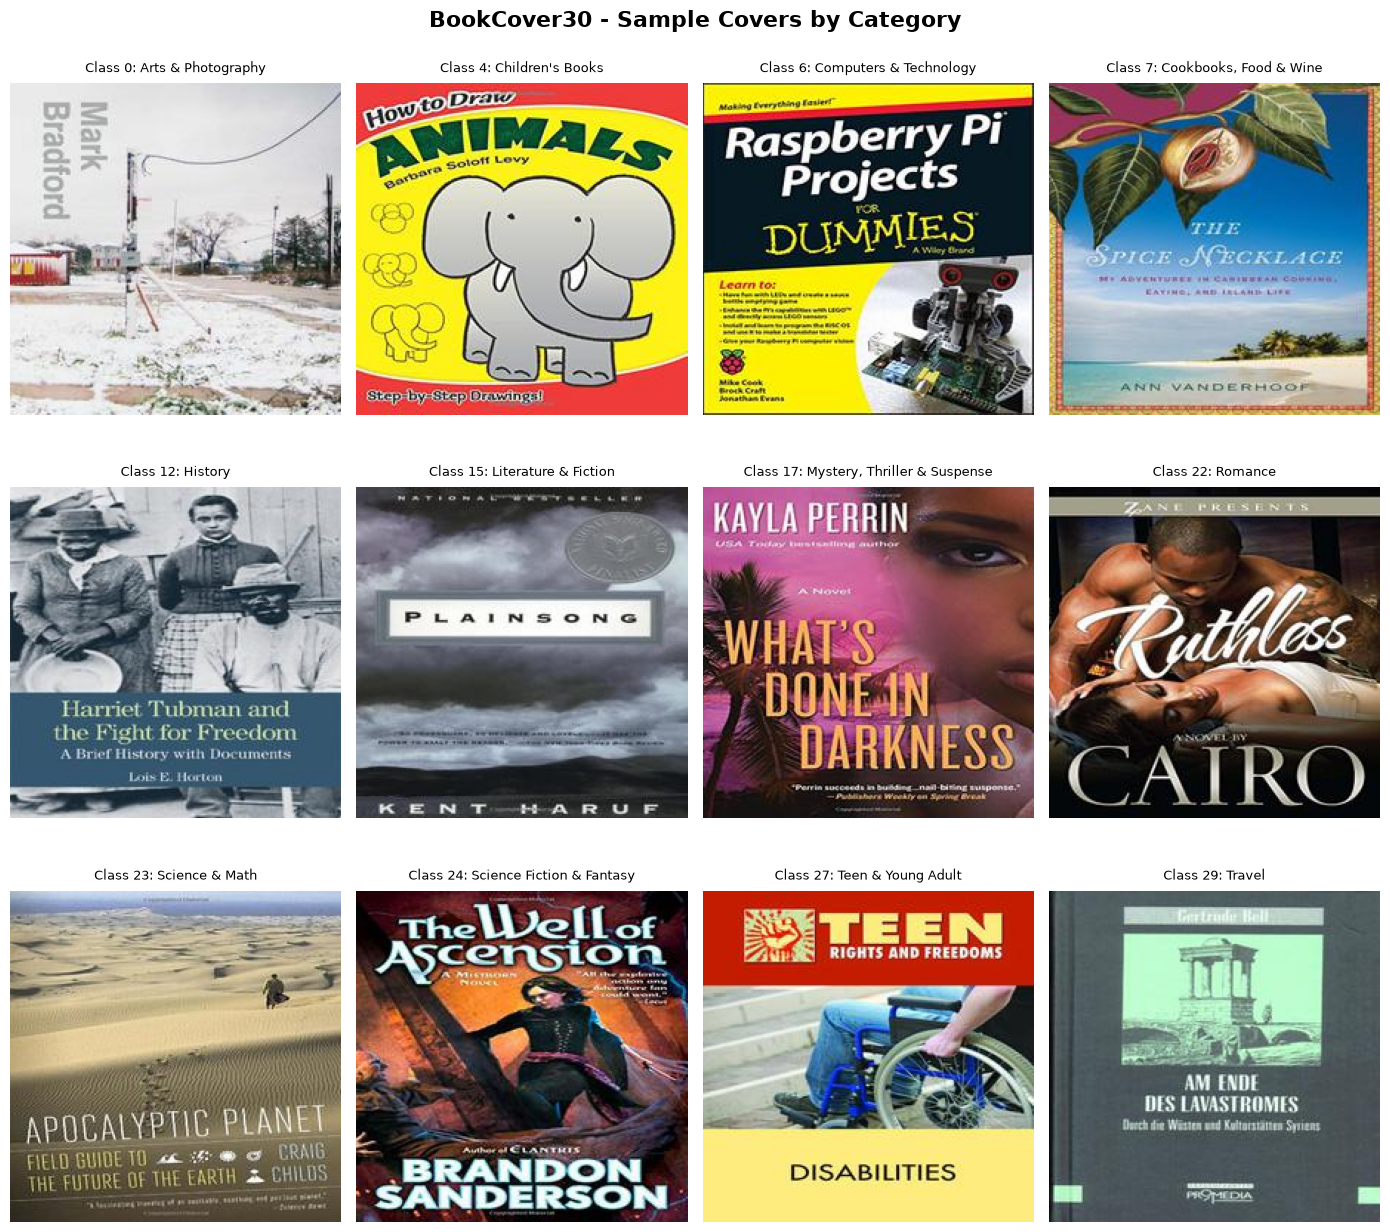

In [21]:
import matplotlib.pyplot as plt
from PIL import Image

# Farklı kategorileri temsil eden 12 sınıf seçiyoruz.
selected_labels = [0, 4, 6, 7, 12, 15, 17, 22, 23, 24, 27, 29]

# Dosya adından kategori adına ulaşmak için eşleme oluşturuyoruz.
category_by_filename = train_csv.set_index("filename")["category"]

fig, axes = plt.subplots(3, 4, figsize=(14, 13))

for ax, label in zip(axes.flat, selected_labels):

    # İlgili kategoriden rastgele ama tekrarlanabilir bir örnek seç.
    sample = train_split[
        train_split["label"] == label
    ].sample(n=1, random_state=42).iloc[0]

    filename = sample["filename"]
    category = category_by_filename.loc[filename]

    # Görüntüyü oku.
    image_path = IMAGE_DIR / filename

    with Image.open(image_path) as img:
        image = img.convert("RGB")
        ax.imshow(image)

    ax.set_title(
        f"Class {label}: {category}",
        fontsize=9,
        pad=8
    )

    ax.axis("off")

plt.suptitle(
    "BookCover30 - Sample Covers by Category",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Grafiği rapor için kaydet.
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    REPORTS_DIR / "sample_book_covers.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

## Train / Validation / Test Distribution

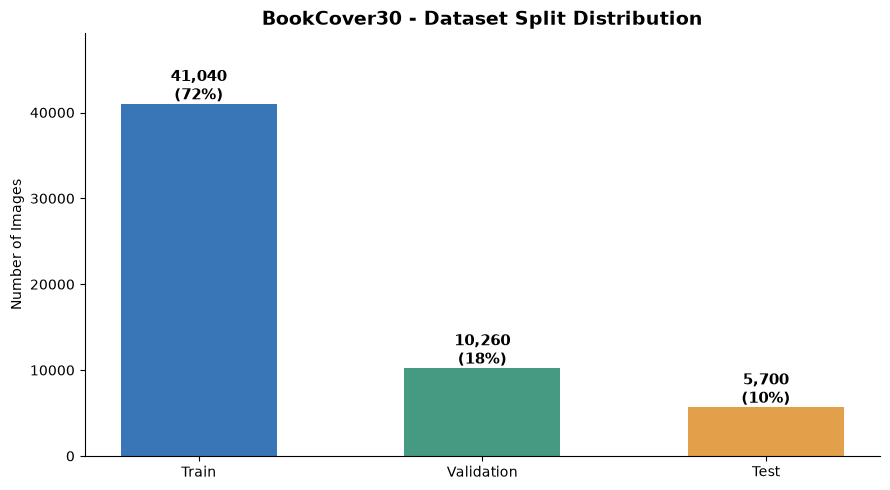

In [23]:
split_names = ["Train", "Validation", "Test"]
split_counts = [
    len(train_split),
    len(val_split),
    len(test_df)
]

split_colors = ["#3976B8", "#459B81", "#E3A04B"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    split_names,
    split_counts,
    color=split_colors,
    width=0.55
)

for bar, count in zip(bars, split_counts):
    percentage = count / sum(split_counts) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 500,
        f"{count:,}\n({percentage:.0f}%)",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "BookCover30 - Dataset Split Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Number of Images")
ax.set_ylim(0, max(split_counts) * 1.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "split_distribution.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()